# 20. Write a python program to perform region-based segmentation and thresholding.

In [18]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [19]:
img = cv2.imread('image.jpeg', 0)
rows, cols = img.shape

In [20]:
# Thresholding
thresh = np.zeros((rows, cols), dtype=np.uint8)

for i in range(rows):
    for j in range(cols):
        if img[i, j] > 127:
            thresh[i, j] = 255

In [21]:
# Region-based segmentation
segmented = np.zeros((rows, cols), dtype=np.uint8)

seed_x, seed_y = 100, 100
seed_value = int(img[seed_x, seed_y])

stack = [(seed_x, seed_y)]
visited = np.zeros((rows, cols), dtype=bool)

while stack:
    x, y = stack.pop()

    if x < 0 or x >= rows or y < 0 or y >= cols:
        continue

    if visited[x, y]:
        continue

    visited[x, y] = True

    if abs(int(img[x, y]) - seed_value) <= 10:
        segmented[x, y] = 255

        stack.append((x-1, y))
        stack.append((x+1, y))
        stack.append((x, y-1))
        stack.append((x, y+1))

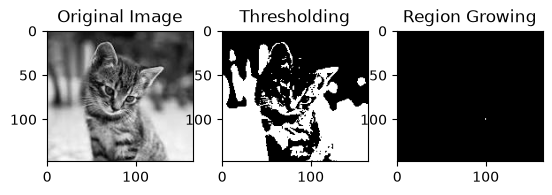

In [22]:
# Display results
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Image')

plt.subplot(1, 3, 2)
plt.imshow(thresh, cmap='gray')
plt.title('Thresholding')

plt.subplot(1, 3, 3)
plt.imshow(segmented, cmap='gray')
plt.title('Region Growing')

plt.show()